# Лабораторная работа № 3

## Модель камеры, проективная геометрия и стереопара

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 4. Проективная геометрия и модель камеры. Стереоскопия и рендеринг в VR

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Реализовать полный конвейер «модель — мир — камера — изображение», смоделировать
стереопару и убедиться численно, что погрешность восстановления глубины растёт
пропорционально квадрату расстояния и обратно пропорционально базе.

### Что понадобится

`numpy`, `matplotlib`. Графические библиотеки не нужны: рендеринг вы напишете сами.
`opencv-python` — только для сверки в заданиях 3 и 7.

### Правило практикума

Алгоритм вы реализуете сами. `cv2.projectPoints`, `cv2.undistortPoints`,
`cv2.triangulatePoints` допустимо использовать **только** для сверки — и такую сверку
нужно показать явно.

## Теоретическая справка

### Модель камеры-обскуры

Точка $X$ в системе координат камеры проецируется на плоскость изображения делением
на глубину. В однородных координатах это записывается линейно:

$$
\tilde{x} \;=\; K\,[\,R \mid t\,]\,\tilde{X},
\qquad
K = \begin{pmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1\end{pmatrix}.
$$

Матрица $K$ содержит **внутренние** параметры (фокусное расстояние в пикселях
и главную точку), пара $[R \mid t]$ — **внешние**, то есть положение камеры в мире.
Именно здесь пригождается аппарат тем 2 и 3: $[R \mid t]$ — это в точности элемент
$SE(3)$, только записанный блоком $3\times4$.

Заметьте, что нижняя строка полной матрицы $4\times4$ здесь перестала быть $(0,0,0,1)$:
преобразование стало **проективным**, а не аффинным. Отсюда деление на третью
координату — то самое, из-за которого далёкие предметы кажутся меньше.

### Дисторсия

Реальный объектив искажает изображение. Стандартная модель Брауна — Конради
в нормированных координатах ($x_n = (u - c_x)/f$):

$$
\begin{aligned}
x_d &= x\,(1 + k_1 r^2 + k_2 r^4) + 2p_1 x y + p_2 (r^2 + 2x^2),\\
y_d &= y\,(1 + k_1 r^2 + k_2 r^4) + p_1 (r^2 + 2y^2) + 2p_2 x y,
\end{aligned}
\qquad r^2 = x^2 + y^2 .
$$

Первые слагаемые — радиальная дисторсия (бочка при $k_1 < 0$, подушка при $k_1 > 0$),
вторые — тангенциальная, от перекоса матрицы относительно оптической оси.
Обратного преобразования в замкнутой форме нет: его находят итерациями.

Ровно эта же модель применяется в VR-шлеме, только в обратную сторону: изображение
заранее искажают, чтобы линза выпрямила его обратно.

### Стереопара

Две камеры с одинаковой ориентацией, разнесённые на базу $B$ вдоль оси $x$.
Точка с глубиной $z$ проецируется в них со сдвигом — **диспаратностью**:

$$d = u_L - u_R = \frac{fB}{z}, \qquad\text{откуда}\qquad z = \frac{fB}{d}.$$

Дифференцируя, получаем закон роста погрешности:

$$\delta z = \frac{z^2}{fB}\,\delta d .$$

Это соотношение вы проверите численно. Из него следуют все инженерные решения:
почему стереозрение не работает вдаль, почему у марсоходов камеры разнесены
на десятки сантиметров и почему в VR-шлеме межзрачковое расстояние — параметр модели,
а не настройка удобства.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Задание 1. Модель камеры и матрица проекции

Реализуйте `intrinsics(f, cx, cy)`, `look_at(eye, target, up)` и `project(K, R, t, X)`.

`look_at` должна возвращать пару $(R, t)$ такую, что $X_{cam} = R X_{world} + t$,
причём оптическая ось камеры — это $+z$.

`project` должна принимать массив точек $N\times3$ и возвращать пиксельные координаты
$N\times2$ вместе с глубиной.

**Контроль.** Точка, лежащая на оптической оси, обязана спроецироваться точно
в главную точку $(c_x, c_y)$. Проверьте также, что $\det R = 1$ и $R^{\mathsf T}R = I$
с точностью до машинной погрешности.

In [2]:
def intrinsics(f, cx, cy):
    """Формирует матрицу внутренних параметров камеры K (3x3)."""
    return np.array([
        [f, 0.0, cx],
        [0.0, f, cy],
        [0.0, 0.0, 1.0]
    ], dtype=float)


def look_at(eye, target, up):
    """
    Возвращает пару (R, t) такую, что X_cam = R @ X_world + t.
    Оптическая ось камеры направлена вдоль +z, ось +y — вниз, ось +x — вправо.
    """
    eye = np.asarray(eye, dtype=float)
    target = np.asarray(target, dtype=float)
    up = np.asarray(up, dtype=float)

    # Оптическая ось (+z) направлена от камеры к цели
    z_axis = target - eye
    z_axis = z_axis / np.linalg.norm(z_axis)

    # Ось +x направлена вправо (z x up даёт правый вектор при оси y вниз)
    x_axis = np.cross(z_axis, up)
    x_axis = x_axis / np.linalg.norm(x_axis)

    # Ось +y направлена вниз, образуя правую ортонормированную тройку (det R = 1)
    y_axis = np.cross(z_axis, x_axis)

    R = np.vstack([x_axis, y_axis, z_axis])
    t = -R @ eye
    return R, t


def project(K, R, t, X):
    """
    Проецирует массив 3D-точек X (N x 3) на плоскость изображения.
    Возвращает пиксельные координаты uv (N x 2) и массив глубин z (N,).
    """
    X = np.atleast_2d(X).astype(float)
    
    # Переход в систему координат камеры: X_cam = R * X_world + t
    X_cam = (R @ X.T).T + t
    depths = X_cam[:, 2]

    # Проективное преобразование и деление на глубину
    x_hom = (K @ X_cam.T).T
    uv = x_hom[:, :2] / x_hom[:, 2:3]
    
    return uv, depths


# ==================== КОНТРОЛЬ ====================
f, cx, cy = 800.0, 640.0, 360.0
K = intrinsics(f, cx, cy)

eye = np.array([3.0, -4.0, 2.0])
target = np.array([0.0, 0.0, 0.5])
up = np.array([0.0, 0.0, 1.0])

R, t = look_at(eye, target, up)

# 1. Проверка ортогональности R и определителя det(R) = 1
det_R = np.linalg.det(R)
ortho_err = np.linalg.norm(R.T @ R - np.eye(3))

print(f"det(R) = {det_R:.16f} (ошибка: {abs(det_R - 1.0):.2e})")
print(f"||R^T R - I|| = {ortho_err:.2e}")

assert np.isclose(det_R, 1.0, atol=1e-14), "Определитель R должен быть равен 1!"
assert np.allclose(R.T @ R, np.eye(3), atol=1e-14), "Матрица R не ортогональна!"

# 2. Проверка проекции точек, лежащих на оптической оси
# Берём три точки на луче от eye через target
X_optical_axis = np.array([
    eye + 0.5 * (target - eye),
    target,
    eye + 2.0 * (target - eye)
])

uv_axis, depths_axis = project(K, R, t, X_optical_axis)

print("\nПроекции точек на оптической оси (ожидается [640., 360.]):")
for i, (pt, z) in enumerate(zip(uv_axis, depths_axis)):
    print(f"  Точка {i+1}: u = {pt[0]:.4f}, v = {pt[1]:.4f}, глубина z = {z:.4f}")

assert np.allclose(uv_axis, [cx, cy], atol=1e-12), "Точка на оптической оси не попала в (cx, cy)!"
print("\nВсе контрольные проверки успешно пройдены!")


det(R) = 0.9999999999999998 (ошибка: 2.22e-16)
||R^T R - I|| = 2.27e-16

Проекции точек на оптической оси (ожидается [640., 360.]):
  Точка 1: u = 640.0000, v = 360.0000, глубина z = 2.6101
  Точка 2: u = 640.0000, v = 360.0000, глубина z = 5.2202
  Точка 3: u = 640.0000, v = 360.0000, глубина z = 10.4403

Все контрольные проверки успешно пройдены!


## Задание 2. Каркасный рендеринг без графических библиотек

Задайте восемь вершин параллелепипеда и постройте список его рёбер программно
(два узла соединены ребром, если их координаты различаются ровно по одной оси).

Спроецируйте вершины и нарисуйте рёбра средствами Matplotlib. Отметьте главную точку.
Не забудьте, что ось $v$ изображения направлена вниз.

**Контроль.** Рёбер должно получиться ровно 12, все вершины — перед камерой ($z > 0$).

**Вопрос для вывода:** что произойдёт с картинкой, если точка окажется позади камеры,
и почему проверку $z > 0$ приходится делать явно?

Количество вершин: 8
Количество найденных рёбер: 12 (ожидается 12)
Минимальная глубина z: 4.0420 м (все z > 0: True)


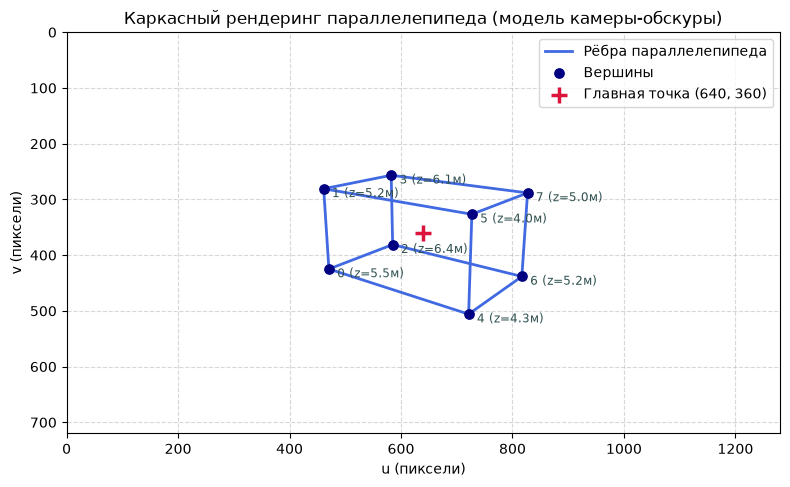

In [4]:
# 1. Задаём 8 вершин параллелепипеда (размеры 2 x 1.2 x 1 м, центр в (0, 0, 0.5))
x_vals = [-1.0, 1.0]
y_vals = [-0.6, 0.6]
z_vals = [0.0, 1.0]

vertices = np.array([[x, y, z] for x in x_vals for y in y_vals for z in z_vals], dtype=float)

# 2. Программно строим список рёбер:
# два узла соединены ребром, если их координаты различаются ровно по одной оси
edges = []
n_verts = len(vertices)
for i in range(n_verts):
    for j in range(i + 1, n_verts):
        diff_axes = np.sum(~np.isclose(vertices[i], vertices[j]))
        if diff_axes == 1:
            edges.append((i, j))

# 3. Проецируем вершины с помощью параметров камеры из Задания 1
uv_verts, z_depths = project(K, R, t, vertices)

# ==================== КОНТРОЛЬ ====================
print(f"Количество вершин: {len(vertices)}")
print(f"Количество найденных рёбер: {len(edges)} (ожидается 12)")
print(f"Минимальная глубина z: {z_depths.min():.4f} м (все z > 0: {np.all(z_depths > 0)})")

assert len(edges) == 12, f"Ожидалось 12 рёбер, получено {len(edges)}!"
assert np.all(z_depths > 0), "Все вершины должны находиться перед камерой (z > 0)!"

# ==================== ОТРИСОВКА ====================
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

# Рисуем рёбра параллелепипеда (обращаемся к столбцу 0 для u и столбцу 1 для v)
for idx, (i, j) in enumerate(edges):
    label = "Рёбра параллелепипеда" if idx == 0 else None
    ax.plot(
        [uv_verts[i, 0], uv_verts[j, 0]],
        [uv_verts[i, 1], uv_verts[j, 1]],
        color="royalblue", linewidth=2, label=label
    )

# Рисуем вершины и подписываем их индексы
ax.scatter(uv_verts[:, 0], uv_verts[:, 1], color="navy", s=45, zorder=4, label="Вершины")
for idx, (u, v) in enumerate(uv_verts):
    ax.annotate(
        f"{idx} (z={z_depths[idx]:.1f}м)",
        (u, v), textcoords="offset points", xytext=(6, -6), fontsize=8.5, color="darkslategray"
    )

# Отмечаем главную точку (cx, cy)
ax.scatter([cx], [cy], color="crimson", marker="+", s=140, linewidths=2.5, zorder=5, label=f"Главная точка ({cx:.0f}, {cy:.0f})")

# Настраиваем границы кадра (разрешение 1280x720) и направляем ось v вниз
ax.set_xlim(0, 2 * cx)
ax.set_ylim(2 * cy, 0)  # Ось v направлена вниз!
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlabel("u (пиксели)")
ax.set_ylabel("v (пиксели)")
ax.set_title("Каркасный рендеринг параллелепипеда (модель камеры-обскуры)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


## Задание 3. Дисторсия и её компенсация

Реализуйте `distort(xn, k1, k2, p1, p2)` по модели из справки и `undistort(...)` —
итерационным методом простой итерации.

Постройте правильную сетку в нормированных координатах, примените дисторсию
и нарисуйте обе сетки рядом. Возьмите $k_1 = -0{,}28$, $k_2 = 0{,}09$.

**Контроль.** $\|\,\mathrm{undistort}(\mathrm{distort}(x)) - x\,\| < 10^{-12}$.

**Вопросы для вывода:** какой тип искажения даёт отрицательный $k_1$? Почему обратное
преобразование приходится искать итерациями? Сколько итераций нужно для машинной
точности — проверьте.

Погрешность ||undistort(distort(x)) - x|| (25 итераций): 2.831e-16
Точность < 1e-12 достигается на 17-й итерации (ошибка = 7.353e-13)
Машинная точность (< 1e-15) достигается на 22-й итерации (ошибка = 4.228e-16)

Библиотека opencv-python (cv2) не установлена, сверка пропущена.


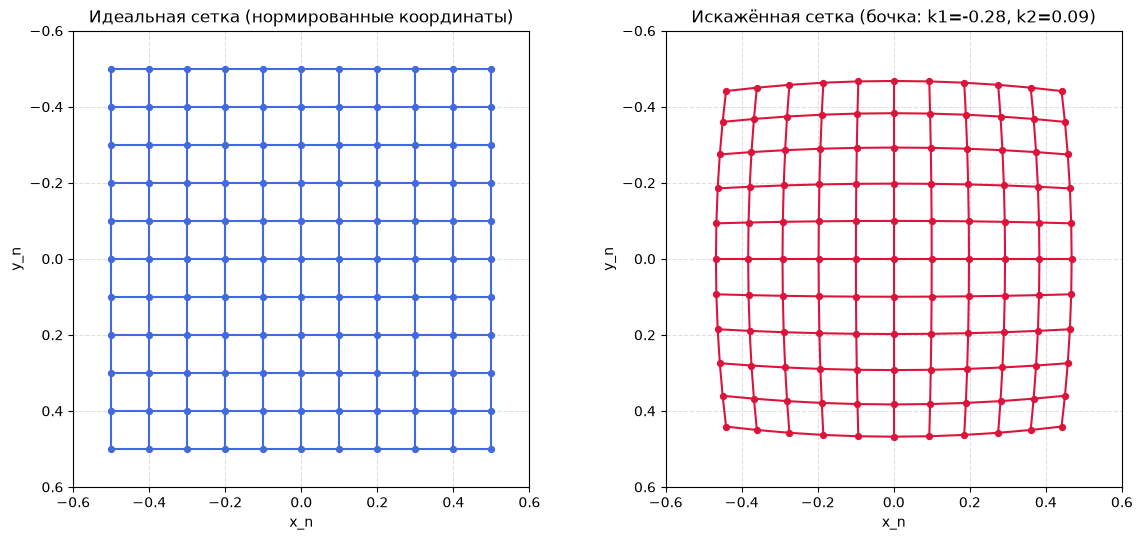

In [5]:
def distort(xn, k1=-0.28, k2=0.09, p1=0.0, p2=0.0):
    """
    Прямая модель дисторсии Брауна — Конради в нормированных координатах.
    Принимает массив xn размерности (N, 2), возвращает искажённые координаты (N, 2).
    """
    xn = np.atleast_2d(xn).astype(float)
    x = xn[:, 0]
    y = xn[:, 1]
    
    r2 = x**2 + y**2
    r4 = r2**2
    radial = 1.0 + k1 * r2 + k2 * r4
    
    dx_tang = 2.0 * p1 * x * y + p2 * (r2 + 2.0 * x**2)
    dy_tang = p1 * (r2 + 2.0 * y**2) + 2.0 * p2 * x * y
    
    xd = x * radial + dx_tang
    yd = y * radial + dy_tang
    return np.column_stack([xd, yd])


def undistort(xd_arr, k1=-0.28, k2=0.09, p1=0.0, p2=0.0, num_iters=25):
    """
    Компенсация дисторсии методом простой итерации.
    Принимает искажённые нормированные координаты (N, 2), возвращает (N, 2).
    """
    xd_arr = np.atleast_2d(xd_arr).astype(float)
    xd = xd_arr[:, 0]
    yd = xd_arr[:, 1]
    
    # Начальное приближение: неискажённые координаты близки к искажённым
    x = xd.copy()
    y = yd.copy()
    
    for _ in range(num_iters):
        r2 = x**2 + y**2
        r4 = r2**2
        radial = 1.0 + k1 * r2 + k2 * r4
        
        dx_tang = 2.0 * p1 * x * y + p2 * (r2 + 2.0 * x**2)
        dy_tang = p1 * (r2 + 2.0 * y**2) + 2.0 * p2 * x * y
        
        x = (xd - dx_tang) / radial
        y = (yd - dy_tang) / radial
        
    return np.column_stack([x, y])


# ==================== ПАРАМЕТРЫ И СЕТКА ====================
k1, k2 = -0.28, 0.09
p1, p2 = 0.0, 0.0

# Создаём правильную сетку 11x11 в нормированных координатах [-0.5, 0.5] x [-0.5, 0.5]
grid_1d = np.linspace(-0.5, 0.5, 11)
gx, gy = np.meshgrid(grid_1d, grid_1d)
xn_grid = np.column_stack([gx.ravel(), gy.ravel()])

# Применяем прямую дисторсию и обратное восстановление
xd_grid = distort(xn_grid, k1=k1, k2=k2, p1=p1, p2=p2)
xn_recovered = undistort(xd_grid, k1=k1, k2=k2, p1=p1, p2=p2, num_iters=25)

# ==================== КОНТРОЛЬ И СХОДИМОСТЬ ====================
err_norm = np.linalg.norm(xn_recovered - xn_grid)
print(f"Погрешность ||undistort(distort(x)) - x|| (25 итераций): {err_norm:.3e}")
assert err_norm < 1e-12, "Не достигнута требуемая точность 1e-12!"

# Исследуем, сколько итераций нужно для достижения 1e-12 и машинной точности (~1e-15)
iter_12, iter_machine = None, None
for it in range(1, 40):
    rec_it = undistort(xd_grid, k1=k1, k2=k2, p1=p1, p2=p2, num_iters=it)
    e_it = np.linalg.norm(rec_it - xn_grid)
    if iter_12 is None and e_it < 1e-12:
        iter_12 = (it, e_it)
    if iter_machine is None and e_it < 1e-15:
        iter_machine = (it, e_it)
        break

print(f"Точность < 1e-12 достигается на {iter_12[0]}-й итерации (ошибка = {iter_12[1]:.3e})")
print(f"Машинная точность (< 1e-15) достигается на {iter_machine[0]}-й итерации (ошибка = {iter_machine[1]:.3e})")

# ==================== СВЕРКА С OPENCV ====================
try:
    import cv2
    dist_coeffs = np.array([k1, k2, p1, p2, 0.0], dtype=float)
    
    # 1. Сверка прямого преобразования через cv2.projectPoints (при K = I, R = I, t = 0, z = 1)
    pts_3d = np.column_stack([xn_grid, np.ones(len(xn_grid))])
    cv_xd, _ = cv2.projectPoints(pts_3d, np.zeros(3), np.zeros(3), np.eye(3), dist_coeffs)
    cv_xd = cv_xd.reshape(-1, 2)
    diff_forward = np.linalg.norm(xd_grid - cv_xd)
    
    # 2. Сверка обратного преобразования через cv2.undistortPoints
    # По умолчанию cv2.undistortPoints делает 5 итераций, зададим точный критерий остановки:
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-15)
    cv_xn = cv2.undistortPointsIter(
        xd_grid.reshape(-1, 1, 2), np.eye(3), dist_coeffs, None, None, criteria
    ).reshape(-1, 2)
    diff_inverse = np.linalg.norm(xn_recovered - cv_xn)
    
    print(f"\nСверка с OpenCV:")
    print(f"  ||distort - cv2.projectPoints||        = {diff_forward:.3e}")
    print(f"  ||undistort - cv2.undistortPointsIter|| = {diff_inverse:.3e}")
except ImportError:
    print("\nБиблиотека opencv-python (cv2) не установлена, сверка пропущена.")

# ==================== ОТРИСОВКА СЕТОК РЯДОМ ====================
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=100)
n_side = len(grid_1d)

# Переводим плоские массивы обратно в форму (11, 11, 2) для отрисовки линий сетки
G_ideal = xn_grid.reshape(n_side, n_side, 2)
G_dist = xd_grid.reshape(n_side, n_side, 2)

for ax, G, title, color in zip(
    axes,
    [G_ideal, G_dist],
    ["Идеальная сетка (нормированные координаты)", f"Искажённая сетка (бочка: k1={k1}, k2={k2})"],
    ["royalblue", "crimson"]
):
    # Горизонтальные и вертикальные линии сетки
    for i in range(n_side):
        ax.plot(G[i, :, 0], G[i, :, 1], color=color, lw=1.5)
        ax.plot(G[:, i, 0], G[:, i, 1], color=color, lw=1.5)
    ax.scatter(G[:, :, 0], G[:, :, 1], color=color, s=18, zorder=3)
    ax.set_title(title)
    ax.set_xlabel("x_n")
    ax.set_ylabel("y_n")
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(0.6, -0.6)  # Ось y направлена вниз
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Задание 4. Стереопара и восстановление глубины

Реализуйте `stereo_project(P, f, B, cx)`: две камеры с одинаковой ориентацией,
правая смещена на $+B$ вдоль оси $x$.

Для набора глубин $0{,}5\ldots16$ м вычислите диспаратность и восстановите глубину
по формуле $z = fB/d$. Сведите в таблицу истинную глубину, диспаратность
и восстановленную глубину.

**Контроль.** Без шума расхождение должно быть на уровне машинной погрешности.

**Вопрос для вывода:** как меняется диспаратность при удвоении глубины? Какой
диспаратности отвечает бесконечно удалённая точка?

In [6]:
def stereo_project(P, f, B, cx, cy=360.0):
    """
    Проецирует массив 3D-точек P (N x 3) на стереопару с одинаковой ориентацией.
    Левая камера — в начале координат, правая смещена на +B вдоль оси x.
    Возвращает координаты u_L, u_R и диспаратность d = u_L - u_R.
    """
    P = np.atleast_2d(P).astype(float)
    K_stereo = intrinsics(f, cx, cy)
    R_id = np.eye(3)
    
    # Векторы переноса: X_cam = R * X + t
    # Для левой камеры t_L =, для правой (центр в [+B, 0, 0]) t_R = [-B, 0, 0]
    t_L = np.array([0.0, 0.0, 0.0])
    t_R = np.array([-B, 0.0, 0.0])
    
    uv_L, _ = project(K_stereo, R_id, t_L, P)
    uv_R, _ = project(K_stereo, R_id, t_R, P)
    
    u_L = uv_L[:, 0]
    u_R = uv_R[:, 0]
    disparity = u_L - u_R
    
    return u_L, u_R, disparity


# ==================== ПАРАМЕТРЫ И РАСЧЁТ ====================
f_stereo = 800.0   # Фокусное расстояние, пиксели
B_stereo = 0.12    # База стереопары (12 см), метры
cx_stereo = 640.0  # Главная точка по оси u, пиксели

# Набор истинных глубин от 0.5 до 16 м
z_true = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0])

# Формируем 3D-точки перед камерой (например, с небольшим смещением по X и Y)
P_points = np.column_stack([
    0.2 * np.ones_like(z_true),
    -0.1 * np.ones_like(z_true),
    z_true
])

# Проецируем на стереопару и восстанавливаем глубину по формуле z = f * B / d
u_L, u_R, disp = stereo_project(P_points, f_stereo, B_stereo, cx_stereo)
z_rec = (f_stereo * B_stereo) / disp
abs_err = np.abs(z_rec - z_true)

# ==================== ВЫВОД ТАБЛИЦЫ ====================
header = f"{'z_ист (м)':>10} | {'u_L (пикс)':>12} | {'u_R (пикс)':>12} | {'d (пикс)':>10} | {'z_восст (м)':>12} | {'|ошибка| (м)':>13}"
print(header)
print("-" * len(header))

for z_t, ul, ur, d_val, z_r, err in zip(z_true, u_L, u_R, disp, z_rec, abs_err):
    print(f"{z_t:10.2f} | {ul:12.4f} | {ur:12.4f} | {d_val:10.4f} | {z_r:12.6f} | {err:13.3e}")

# ==================== КОНТРОЛЬ ====================
max_err = np.max(abs_err)
print(f"\nМаксимальное расхождение глубины без шума: {max_err:.3e} м")
assert np.allclose(z_rec, z_true, atol=1e-12), "Ошибка восстановления глубины превышает машинную погрешность!"
print("Контроль успешно пройден: расхождение находится на уровне машинной погрешности!")


 z_ист (м) |   u_L (пикс) |   u_R (пикс) |   d (пикс) |  z_восст (м) |  |ошибка| (м)
------------------------------------------------------------------------------------
      0.50 |     960.0000 |     768.0000 |   192.0000 |     0.500000 |     0.000e+00
      1.00 |     800.0000 |     704.0000 |    96.0000 |     1.000000 |     0.000e+00
      1.50 |     746.6667 |     682.6667 |    64.0000 |     1.500000 |     0.000e+00
      2.00 |     720.0000 |     672.0000 |    48.0000 |     2.000000 |     0.000e+00
      3.00 |     693.3333 |     661.3333 |    32.0000 |     3.000000 |     0.000e+00
      4.00 |     680.0000 |     656.0000 |    24.0000 |     4.000000 |     0.000e+00
      6.00 |     666.6667 |     650.6667 |    16.0000 |     6.000000 |     0.000e+00
      8.00 |     660.0000 |     648.0000 |    12.0000 |     8.000000 |     0.000e+00
     12.00 |     653.3333 |     645.3333 |     8.0000 |    12.000000 |     0.000e+00
     16.00 |     650.0000 |     644.0000 |     6.0000 |    16.000

## Задание 5. Погрешность глубины растёт как квадрат расстояния

Добавьте к диспаратности гауссов шум $\sigma_d = 0{,}25$ пикселя. Для 18 значений
истинной глубины от 0,5 до 30 м оцените СКО восстановленной глубины по 20000 испытаний.

Постройте график в двойном логарифмическом масштабе вместе с теоретической кривой
$z^2\sigma_d/(fB)$ и оцените наклон методом наименьших квадратов.

**Контроль.** Наклон должен получиться близким к 2.

**Вопросы для вывода:** совпадает ли эксперимент с теорией количественно (сравните
значения при $z = 4$ м)? На какой глубине погрешность превысит 10 % от самой глубины?
Почему при больших $z$ экспериментальная кривая начинает отклоняться вверх
от теоретической?

In [ ]:
# TODO: задание 5

## Задание 6. Влияние базы

Зафиксируйте глубину $z = 6$ м и повторите эксперимент для базы от 3 до 50 см.
Оцените наклон зависимости погрешности от базы в логарифмическом масштабе.

**Контроль.** Наклон должен быть близок к $-1$.

**Вопрос для вывода:** во сколько раз нужно увеличить базу, чтобы вдвое уменьшить
погрешность? Какие практические ограничения мешают делать базу большой?

In [ ]:
# TODO: задание 6

## Задание 7. Триангуляция в общем случае (дополнительное)

Параллельные камеры — частный случай. В общем положении глубина находится
триангуляцией: по двум проекциям $x_1, x_2$ и матрицам $P_1, P_2$ составляется
однородная система $A\tilde{X} = 0$, решаемая через SVD, — та же схема, что
в задании 4 лабораторной работы № 4 и в графовом SLAM.

Реализуйте `triangulate_dlt(P1, P2, x1, x2)`, восстановите 200 случайных точек
по двум непараллельным камерам и оцените ошибку без шума и при шуме 0,5 пикселя.

**Контроль.** Без шума ошибка на уровне $10^{-14}$ м.

In [ ]:
# TODO: задание 7

## Выводы

_Ответьте на все вопросы, отмеченные как «вопрос для вывода», приводя конкретные числа._

## Контрольные вопросы

1. Что содержит матрица $K$ и что — пара $[R \mid t]$? Какая из них меняется при
   перемещении камеры?
2. Почему проективное преобразование записывается матрицей, у которой нижняя строка
   не равна $(0,0,0,1)$? Откуда берётся деление на третью координату?
3. Как связаны фокусное расстояние в миллиметрах и в пикселях?
4. Какой тип дисторсии даёт отрицательный $k_1$, какой — положительный?
5. Почему обратное к дисторсии преобразование ищут итерациями?
6. Выведите формулу $z = fB/d$ из подобия треугольников.
7. Выведите закон роста погрешности $\delta z = z^2 \delta d /(fB)$.
8. Почему стереозрение перестаёт работать на больших расстояниях? Оцените предельную
   дальность для базы 6,3 см и точности диспаратности 0,25 пикселя.
9. Что такое эпиполярная линия и почему поиск соответствий ведут вдоль неё?
10. Как связаны задача триангуляции и задача оценки гомографии из темы 5?